### Inlezen dataset

#### Stap 0: Preprocessing
Beschrijf welke stappen jullie doen voor preprocessing

In [60]:
# Code voor preprocessing van de data

#### Stap 1: EDA
Exploratory Data Analysis.

In [49]:
# Lees de opgeschoonde dataset; laad jaar en pagina-aantal als gehele getallen.
from pathlib import Path

import pandas as pd

dataset_path = Path("datasets") / "processed" / "catalogus_opgeschoond.csv"
df = pd.read_csv(
    dataset_path,
    encoding="utf-8",
    sep=";",
    dtype={"aantal_paginas": "Int64", "publicatiejaar": "Int64"},
)

df.describe()

,aantal_paginas,publicatiejaar,Gemiddelde beoordeling
count,263.0,210.0,183.000000
mean,179.368821,2015.533333,3.273770
std,114.848111,8.880996,0.352963
min,0.0,1998.0,2.200000
25%,111.5,2013.0,3.000000
50%,179.0,2018.0,3.300000
75%,264.5,2023.0,3.500000
max,400.0,2025.0,4.000000


In [50]:
# Toon alle kolomnamen van de opgeschoonde dataset.
df.columns.tolist()

['Titel',
 'Auteur',
 'Korte omschrijving',
 'Type materiaal',
 'Niveau',
 'genre',
 'trefwoorden',
 'aantal_paginas',
 'doelgroep',
 'publicatiejaar',
 'beschikbaar_formaat',
 'cataloguscode',
 'Gemiddelde beoordeling']

In [51]:
# Toon het datatype dat pandas voor elke kolom gebruikt.
df.dtypes

Titel                         str
Auteur                        str
Korte omschrijving            str
Type materiaal                str
Niveau                        str
genre                         str
trefwoorden                   str
aantal_paginas              Int64
doelgroep                     str
publicatiejaar              Int64
beschikbaar_formaat           str
cataloguscode                 str
Gemiddelde beoordeling    float64
dtype: object

In [52]:
# Toon het aantal rijen en kolommen.
df.shape

(283, 13)

In [53]:
# Bekijk de eerste vijf rijen om de data snel te controleren.
df.head()

,Titel,Auteur,Korte omschrijving,Type materiaal,Niveau,genre,trefwoorden,aantal_paginas,doelgroep,publicatiejaar,beschikbaar_formaat,cataloguscode,Gemiddelde beoordeling
0,het dagboek van anne frank,Anne Frank,Dagboek van een Joods meisje dat tijdens de Tw...,Boek,3F,informatief,WOII; onderduik,265,mbo,2025,pdf,CAT-00001,3.4
1,blauw water,S. van der Vlugt,Spannende thriller waarin een vrouw wordt geco...,Boek,3F,fictie,spanning; stalking,171,mbo,2005,digitaal,CAT-00002,2.5
2,boer vindt vrouw,H. van der Werf,"Toegankelijk verhaal over liefde, relaties en ...",Boek,2F,fictie,liefde; relaties,219,mbo/nt2,2025,digitaal,CAT-00003,3.8
3,cadeau voor u!,Harry Mulisch,Bundel toegankelijke verhalen over verrassende...,Boek,3F,fictie,ontmoeting; verbondenheid,288,mbo,2018,digitaal,CAT-00004,3.9
4,de biecht,Mickey Roorda,Verhaal waarin verborgen geheimen en persoonli...,Boek,2F,fictie,geheimen; schuld,358,mbo/nt2,<NA>,online,CAT-00005,3.1


In [54]:
# Tel ontbrekende waarden per kolom, van veel naar weinig.
df.isna().sum().sort_values(ascending=False)

trefwoorden               134
Gemiddelde beoordeling    100
publicatiejaar             73
beschikbaar_formaat        43
genre                      26
aantal_paginas             20
Auteur                      7
doelgroep                   6
Niveau                      6
Type materiaal              1
Titel                       0
Korte omschrijving          0
cataloguscode               0
dtype: int64

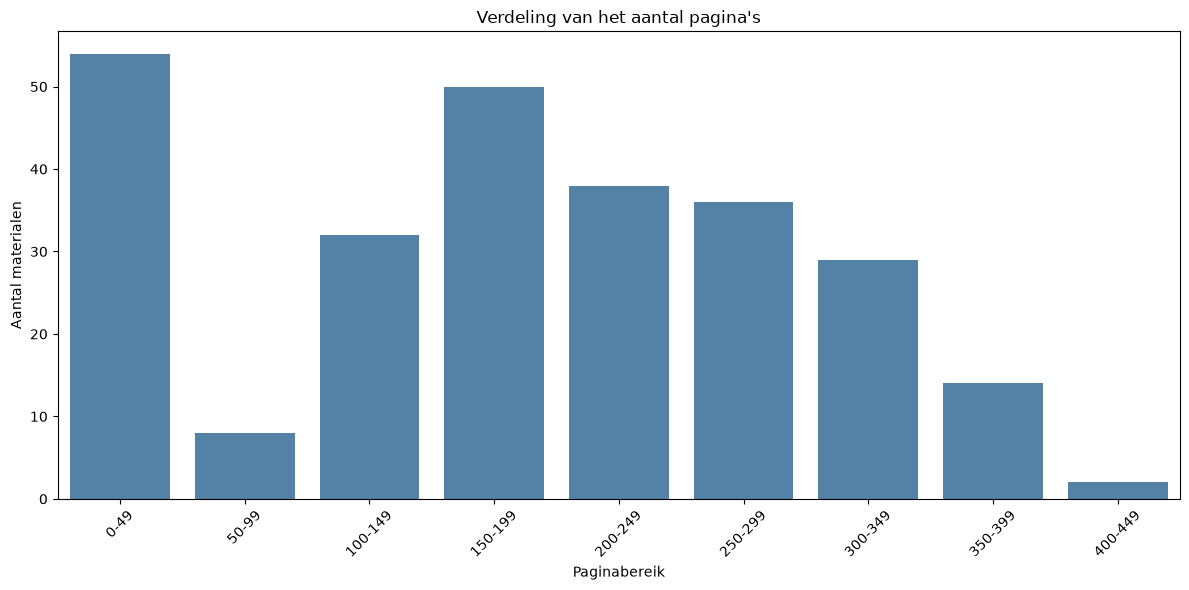

In [55]:
# Toon de verdeling van pagina-aantallen in intervallen van 50 pagina's.
import matplotlib.pyplot as plt
import seaborn as sns

page_counts = df["aantal_paginas"].dropna().astype(int)
bin_width = 50
upper_edge = ((int(page_counts.max()) // bin_width) + 1) * bin_width
bin_edges = list(range(0, upper_edge + 1, bin_width))
bin_labels = [f"{start}-{start + bin_width - 1}" for start in bin_edges[:-1]]
page_ranges = pd.cut(
    page_counts,
    bins=bin_edges,
    labels=bin_labels,
    right=False,
    include_lowest=True,
)
page_distribution = page_ranges.value_counts(sort=False).rename_axis("paginabereik").reset_index(name="aantal")

plt.figure(figsize=(12, 6))
sns.barplot(data=page_distribution, x="paginabereik", y="aantal", color="steelblue", errorbar=None)
plt.title("Verdeling van het aantal pagina's")
plt.xlabel("Paginabereik")
plt.ylabel("Aantal materialen")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

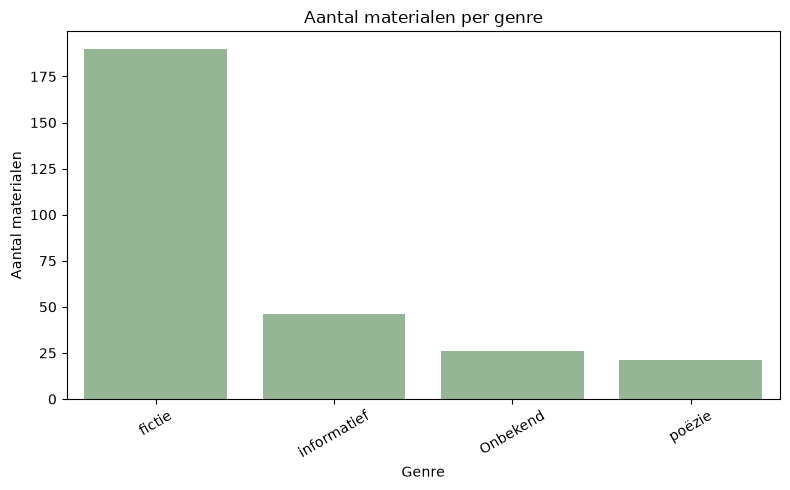

In [56]:
# Toon hoeveel materialen er per genre zijn, inclusief ontbrekende genres.
genre_counts = (
    df["genre"]
    .fillna("Onbekend")
    .value_counts()
    .rename_axis("genre")
    .reset_index(name="aantal")
)

plt.figure(figsize=(8, 5))
sns.barplot(data=genre_counts, x="genre", y="aantal", color="darkseagreen", errorbar=None)
plt.title("Aantal materialen per genre")
plt.xlabel("Genre")
plt.ylabel("Aantal materialen")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

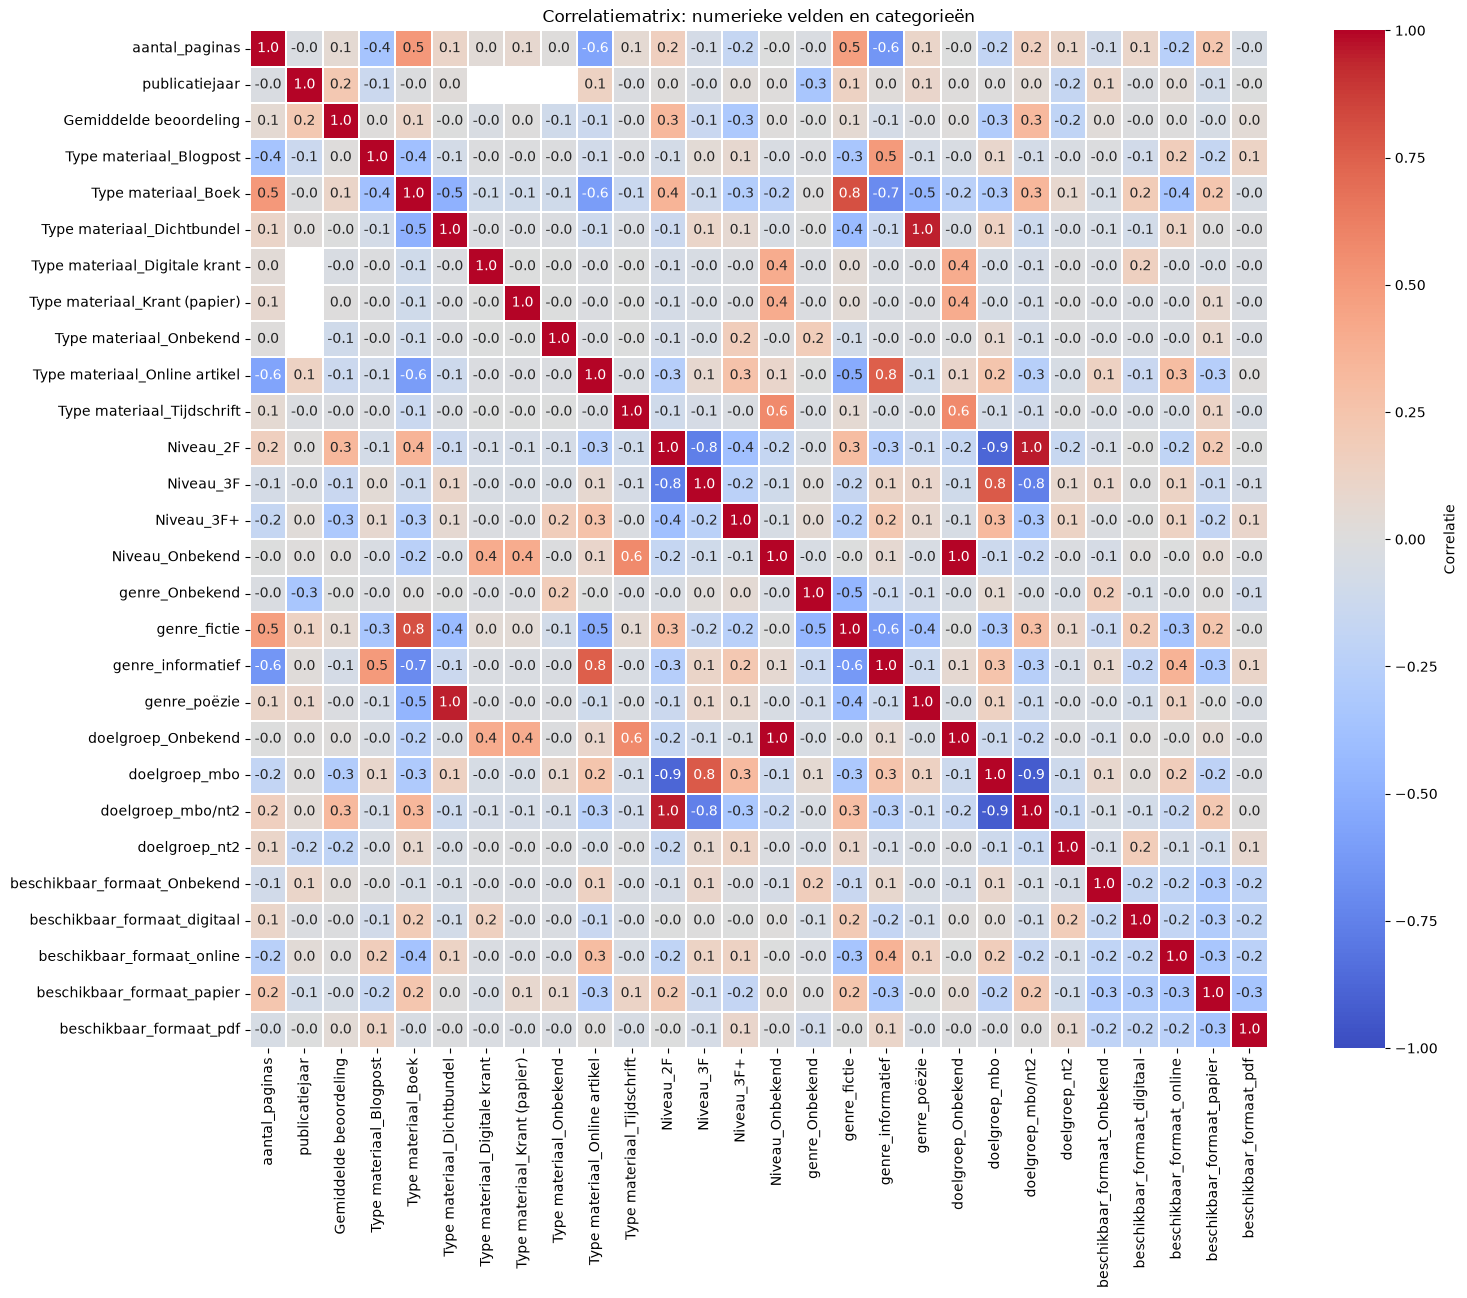

In [57]:
# Bereken correlaties tussen numerieke velden en one-hot gecodeerde categorieën.
import matplotlib.pyplot as plt
import seaborn as sns

numeric_columns = [
    "aantal_paginas",
    "publicatiejaar",
    "Gemiddelde beoordeling",
]
categorical_columns = [
    "Type materiaal",
    "Niveau",
    "genre",
    "doelgroep",
    "beschikbaar_formaat",
]

numeric_data = df[numeric_columns].apply(pd.to_numeric, errors="raise")
encoded_categories = pd.get_dummies(
    df[categorical_columns].fillna("Onbekend"),
    prefix=categorical_columns,
    dtype=int,
)
correlation_data = pd.concat([numeric_data, encoded_categories], axis=1)
correlation_matrix = correlation_data.corr()

plt.figure(figsize=(16, 13))
sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.3,
    cbar_kws={"label": "Correlatie"},
    annot=True,
    fmt=".1f",
)
plt.title("Correlatiematrix: numerieke velden en categorieën")
plt.tight_layout()
plt.show()

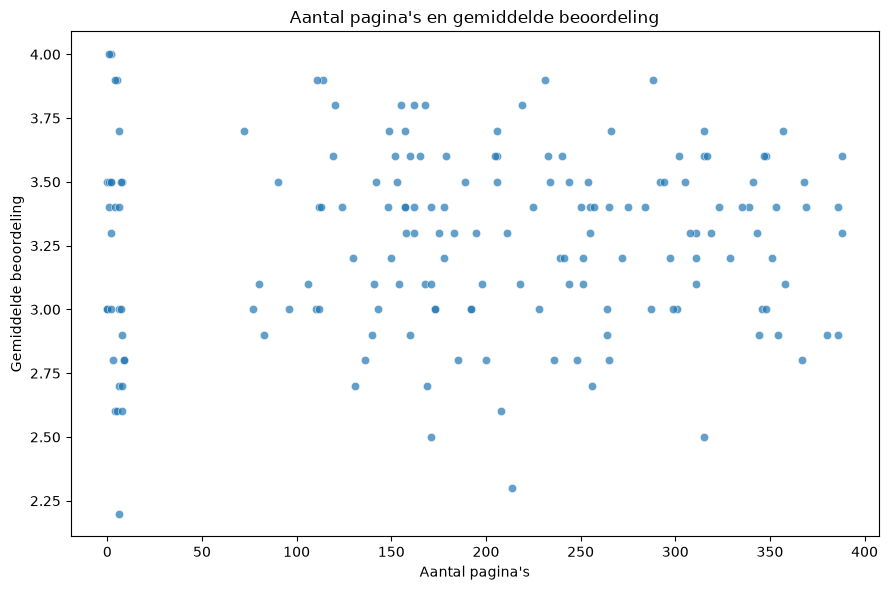

In [58]:
# Vergelijk het aantal pagina's met de gemiddelde beoordeling per materiaal.
scatter_data = df[["aantal_paginas", "Gemiddelde beoordeling"]].dropna()

plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=scatter_data,
    x="aantal_paginas",
    y="Gemiddelde beoordeling",
    alpha=0.7,
)
plt.title("Aantal pagina's en gemiddelde beoordeling")
plt.xlabel("Aantal pagina's")
plt.ylabel("Gemiddelde beoordeling")
plt.tight_layout()
plt.show()

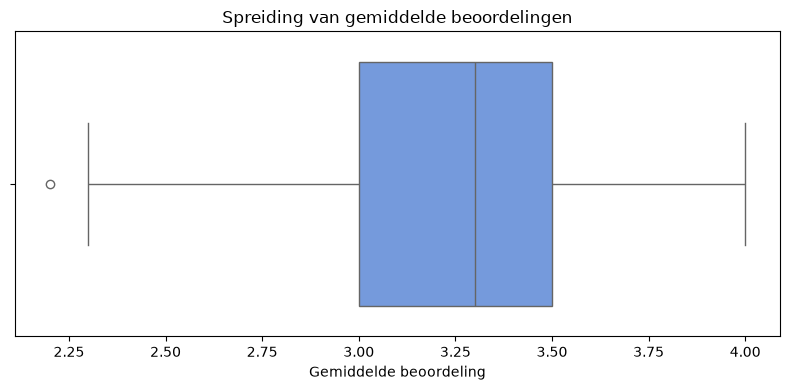

In [59]:
# Toon de spreiding en mediaan van de ingevulde beoordelingen.
rating_data = df["Gemiddelde beoordeling"].dropna()

plt.figure(figsize=(8, 4))
sns.boxplot(x=rating_data, color="cornflowerblue")
plt.title("Spreiding van gemiddelde beoordelingen")
plt.xlabel("Gemiddelde beoordeling")
plt.tight_layout()
plt.show()